# Demo 2: does spatial structure and movement buy forecast skill?

Three COVID models over the 2020-21 season, identical but for their geography and movement.

| model | structure |
|---|---|
| `movement` | 32 counties, commuting flows from ACS (`mm.Pei()`) |
| `county` | the same 32 counties, but nobody moves (`mm.No()`) |
| `state` | 3 states, no spatial resolution within a state |

All three are **scored at the 3 states**: the county models' ensembles are summed to states
inside each realization, before any quantile is taken, because quantiles do not add.

**Hand-maintained.** There is no generator in `scratch/`; edit this directly. The loading,
scoring and figure code lives in `evaluation.py`, shared with the manuscript exporter.

**Reading order.** Section 3 is provenance; read it before any score. Section 5 is the
reproducibility check and currently limits what can be claimed about movement.

## Setup

In [ ]:
# Pick up edits to the analysis package without restarting the kernel. Worth
# having: these modules are edited while this notebook is open, and a kernel holding a
# stale import fails with a confusing AttributeError on a function that is right there
# in the file. After changing the *shape* of `Evaluation` (not just a function body),
# re-run the load cell, since instances keep the class they were built with.
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from manuscript_analysis.demos import export, paths
from manuscript_analysis.demos.covid import evaluation as ev_mod
from manuscript_analysis.demos.covid.models import covid_season
from manuscript_analysis.demos.covid.seasons import seasons
from manuscript_analysis.demos.lib.figures import save_figure, use_manuscript_style

# The notebook's own figures, kept apart from the paper's. `results/figures/` holds
# only what `manuscript_analysis.demos.export` composes; these are the panels on
# their own, for reading. Disposable.
NOTEBOOK_FIGURES = paths.RESULTS / "demos" / "notebook"

use_manuscript_style()
pd.set_option("display.width", 200)

SEASON = seasons["COVID2020"]

# Switch this to "output-r600" once those runs finish; "output" is the R=200 set.
OUTPUT = paths.runs("covid", seed=0)
REPLICATE = paths.runs("covid", seed=1)

print(f"{SEASON.name}: window opens {SEASON.start_date}, {SEASON.weeks} weeks")
print(f"  {SEASON.burn_in_weeks}-week burn-in, {SEASON.horizon_weeks}-week horizon")
print(f"  {len(covid_season.scope().node_ids)} counties -> "
      f"{len(covid_season.state_scope().node_ids)} scored states")

## 1. Run the models

From a terminal, not from here: each fit is single-threaded, so run them in parallel.

```sh
cd demo-covid
python run_season.py models.state_aggregate:model    -n 600 &
python run_season.py models.spatial_movement:county   -n 600 &
python run_season.py models.spatial_movement:movement -n 600 &
wait
```

A folder produced under the same configuration is skipped; a different window, burn-in or
seed forces a re-run.

In [ ]:
from manuscript_analysis.demos.lib.cli import run_season_cli

REALIZATIONS = 600
SPECS = [
    "models.state_aggregate:model",
    "models.spatial_movement:county",
    "models.spatial_movement:movement",
]

# Safe to re-run: a folder produced under the SAME configuration is skipped, and one
# produced under a different window, burn-in, seed or ensemble size is re-run rather
# than silently reused. This runs them one after another; the shell block above runs
# them in parallel, which is what you want for a real run.
for spec in SPECS:
    run_season_cli(
        seasons,
        default_season="COVID2020",
        output_root=lambda seed: paths.runs("covid", seed=seed),
        package="manuscript_analysis.demos.covid",
        argv=[spec, "-n", str(REALIZATIONS)],
    )

## 2. Load and score

`observations.csv` is frozen, and here that is load-bearing rather than a nicety: the
suppressed-death imputation is a random draw, so re-deriving it would move the target the
models are scored against.

The two quantities label the same MMWR week at **opposite ends** (the census by its starting
Sunday, deaths by the ending Saturday), so `evaluation` relabels them onto one convention
before joining. Without that, deaths join nothing at all.

In [3]:
ev = ev_mod.load(OUTPUT)

print(f"forecasts {ev.forecasts[ev_mod.MODELS[0]].shape} "
      f"(origins, horizons, states, quantities, levels)")
print(f"{len(ev.origins)} origins, {ev.origins[0]} to {ev.origins[-1]}")
print(f"horizons {list(ev.horizons)}, scored at {[ev.labels[c] for c in ev.locations]}")
print("all models verified against an identical target")

forecasts (24, 4, 3, 2, 5) (origins, horizons, states, quantities, levels)
24 origins, 2020-10-04T00:00:00.000000000 to 2021-03-14T00:00:00.000000000
horizons [0, 1, 2, 3], scored at ['CT', 'MA', 'NH']
all models verified against an identical target


## 3. Provenance and completeness

In [4]:
provenance = pd.DataFrame([
    {
        "model": name,
        "season": run.info["season"],
        "window": f"{run.info['season_start']} +{run.info['season_weeks']}w",
        "R": run.info["num_realizations"],
        "burn-in": run.info["burn_in_weeks"],
        "horizon": run.info["horizon_weeks"],
        "seed": run.info["seed"],
        "minutes": round(run.info["elapsed_seconds"] / 60, 1),
        "scored at": len(run.info["scoring_locations"]),
        "movement data": run.info["movement_data_mode"],
    }
    for name, run in ev.runs.items()
])
provenance

,model,season,window,R,burn-in,horizon,seed,minutes,scored at,movement data
0,movement,COVID2020,2020-08-09 +35w,600,8,4,0,85.7,3,home
1,county,COVID2020,2020-08-09 +35w,600,8,4,0,34.9,3,home
2,state,COVID2020,2020-08-09 +35w,600,8,4,0,9.0,3,home


In [5]:
# The models must differ ONLY in structure, or the comparison is not controlled.
must_match = ["season", "window", "R", "burn-in", "horizon", "seed"]
differing = [c for c in must_match if provenance[c].nunique() > 1]
assert not differing, f"models were not run identically: {differing}"
print(f"all {len(ev.runs)} models agree on {', '.join(must_match)}")
print("every model is scored at the same 3 states:",
      dict(zip(provenance["model"], provenance["scored at"])))

all 3 models agree on season, window, R, burn-in, horizon, seed
every model is scored at the same 3 states: {'movement': 3, 'county': 3, 'state': 3}


## 4. Forecast skill

Scored per quantity. There is no pooled score across quantities: a hospital census and a
death count are not commensurate, so adding their WIS would mean nothing.

In [6]:
ev_mod.wis_table(ev).round(3)

WIS  rel WIS  cov95  cov50
model    quantity                                
movement census     97.910    1.281  0.753  0.295
         deaths     18.931    1.196  0.872  0.385
county   census    107.348    1.405  0.774  0.288
         deaths     20.171    1.274  0.844  0.382
state    census     76.412    1.000  1.000  0.510
         deaths     15.828    1.000  0.958  0.552

In [7]:
# Per state. `movement / county` is the informative contrast for the movement question:
# same spatial resolution, movement on against movement off.
ev_mod.wis_by_location(ev).round(3)

movement   county    state  movement / state  county / state  movement / county
jurisdiction quantity                                                                                 
CT           census     104.914  113.867   95.954             1.093           1.187              0.921
             deaths      21.565   22.204   18.901             1.141           1.175              0.971
MA           census     150.460  168.623  108.628             1.385           1.552              0.892
             deaths      27.461   30.383   22.158             1.239           1.371              0.904
NH           census      38.354   39.555   24.654             1.556           1.604              0.970
             deaths       7.768    7.924    6.425             1.209           1.233              0.980

## 5. Is it reproducible? Check before believing anything above

Demo 1 learned this the hard way: two conclusions drawn at R = 100 were ensemble artifacts,
and what exposed them was re-running at a **different seed**, not at a different ensemble
size. Comparing two ensemble sizes asks whether the pooled number moves; it does not ask
whether the number is reproducible at a fixed size. Only the second question catches this.

Every model is re-run at seed 1, never a seed-1 model against a seed-0 baseline: the
denominator has to be built exactly like the numerator.

In [8]:
rep = ev_mod.load_replicate() if REPLICATE.exists() else None

if rep is not None:
    rows = []
    for quantity in ev_mod.QUANTITIES:
        for model in ev_mod.MODELS:
            if model == ev_mod.BASELINE:
                continue
            a = ev_mod.relative_pooled(ev, model, quantity)
            b = ev_mod.relative_pooled(rep, model, quantity)
            rows.append({"quantity": quantity, "model": model,
                         "rel WIS seed 0": a, "rel WIS seed 1": b,
                         "geometric mean": np.sqrt(a * b)})
    print(f"scale: {ev.scale}")
    print(pd.DataFrame(rows).round(3).to_string(index=False))

    # The movement question, per state and quantity, at both seeds.
    print("\nmovement / county, and whether the two seeds agree on the sign:")
    agree = 0
    for i, code_ in enumerate(ev.locations):
        for quantity in ev_mod.QUANTITIES:
            a = ev_mod.relative_by_unit(ev, "movement", quantity, against="county")[i]
            b = ev_mod.relative_by_unit(rep, "movement", quantity, against="county")[i]
            same = (a < 1) == (b < 1)
            agree += same
            print(f"  {ev.labels[code_]} {quantity:7s}: "
                  f"seed0 {a:.3f}  seed1 {b:.3f}  {'agree' if same else 'FLIP'}")
    print(f"\n  seeds agree on {agree} of {2 * len(ev.locations)} cells")
else:
    print(f"no replicate at {REPLICATE}; run the models with --seed 1 first")

quantity    model  rel WIS seed 0  rel WIS seed 1  geometric mean
  census movement           1.281           1.350           1.315
  census   county           1.405           1.431           1.418
  deaths movement           1.196           1.251           1.223
  deaths   county           1.274           1.307           1.291

movement / county, and whether the two seeds agree on the sign:
  CT census : seed0 0.921  seed1 0.929  agree
  CT deaths : seed0 0.971  seed1 0.950  agree
  MA census : seed0 0.892  seed1 0.948  agree
  MA deaths : seed0 0.904  seed1 0.965  agree
  NH census : seed0 0.970  seed1 0.965  agree
  NH deaths : seed0 0.980  seed1 0.946  agree

  seeds agree on 6 of 6 cells


## 6. Manuscript figures

Panels of Figure 3 in `drafts/figure-plan-v01.md`. Every one comes from `evaluation.py`, so
the paper and this notebook cannot disagree. Colours are fixed paper-wide, and match Demo 1's
roles: the unstructured baseline grey, structure plus the data driving it blue, the same
structure with that data removed orange.

Every `figure_*` takes a `title`: a string of your own, or `None` for no title, which is
what a panel of a composed multi-panel figure wants. The y axis wording for both
quantities lives in `evaluation.AXIS_LABELS`.

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


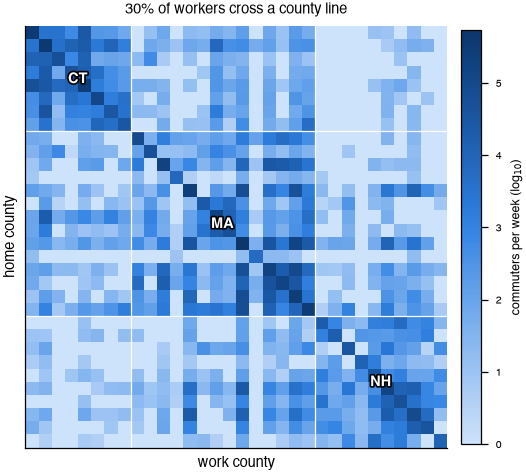

In [9]:
# Figure 3(a): the commuting matrix, which IS the experimental design.
# `movement` uses it as drawn; `county` uses only its diagonal; `state` collapses each
# white-bordered block to one node.
fig = ev_mod.figure_movement_structure()
save_figure(fig, "covid-commuting-matrix", figure_dir=NOTEBOOK_FIGURES)
plt.show()

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


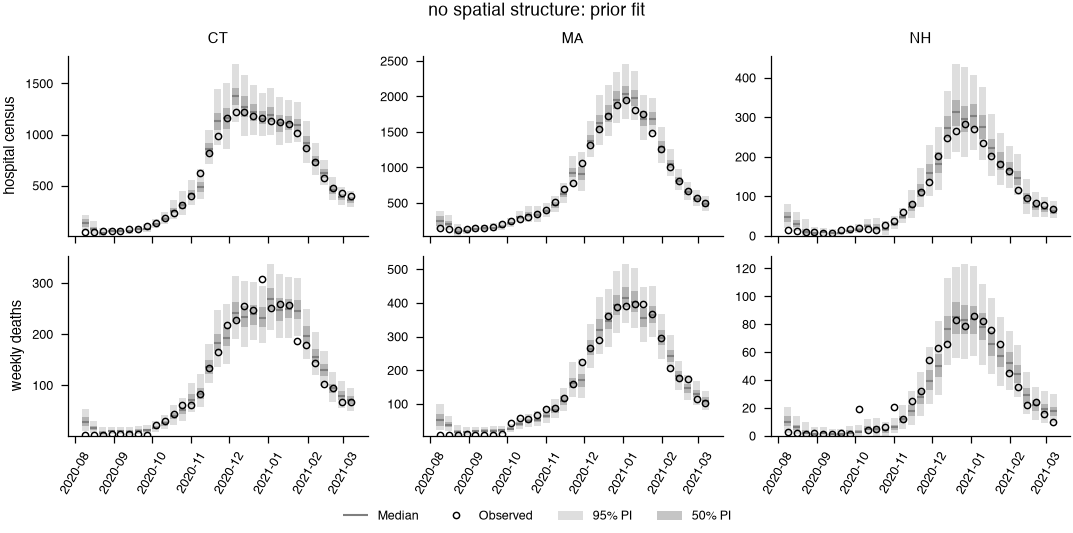

In [10]:
# Figure 3(b): the fit, both quantities, at the state model's own 3 nodes.
# PRIOR, not posterior: the posterior is pulled onto the observation by construction.
fig = ev_mod.figure_fit(ev, "state", series="prior")
save_figure(fig, "covid-state-fit", figure_dir=NOTEBOOK_FIGURES)
plt.show()

In [11]:
# The counties both county-resolved panels show, and the ones Figure 3(c)
# draws: the largest in each state, since a small one sits near zero for most
# of the season. `evaluation.focus_counties` is shared with the exporter, so
# the paper and this notebook cannot show different counties.
FOCUS_COUNTIES = ev_mod.focus_counties()

print("showing", [ev.labels[c] for c in FOCUS_COUNTIES],
      f"of {len(covid_season.scope().node_ids)} counties")


showing ['Fairfield, CT', 'Middlesex, MA', 'Hillsborough, NH'] of 32 counties


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


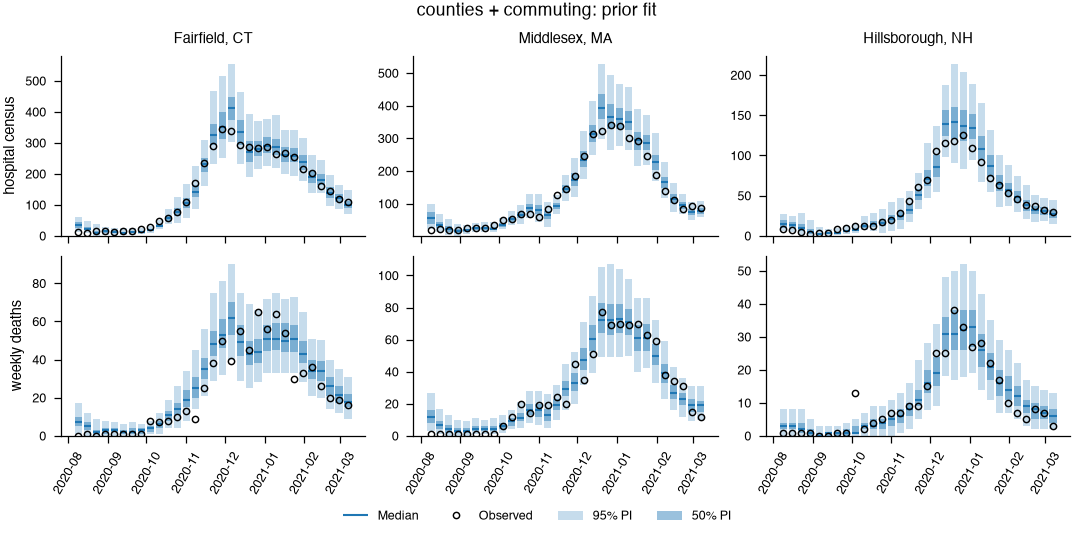

In [12]:
# County-resolved fit: Demo 2's counterpart to Demo 1's age-resolved panel.
fig = ev_mod.figure_fit(ev, "movement", locations=FOCUS_COUNTIES)
save_figure(fig, "covid-county-fit", figure_dir=NOTEBOOK_FIGURES)
plt.show()

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


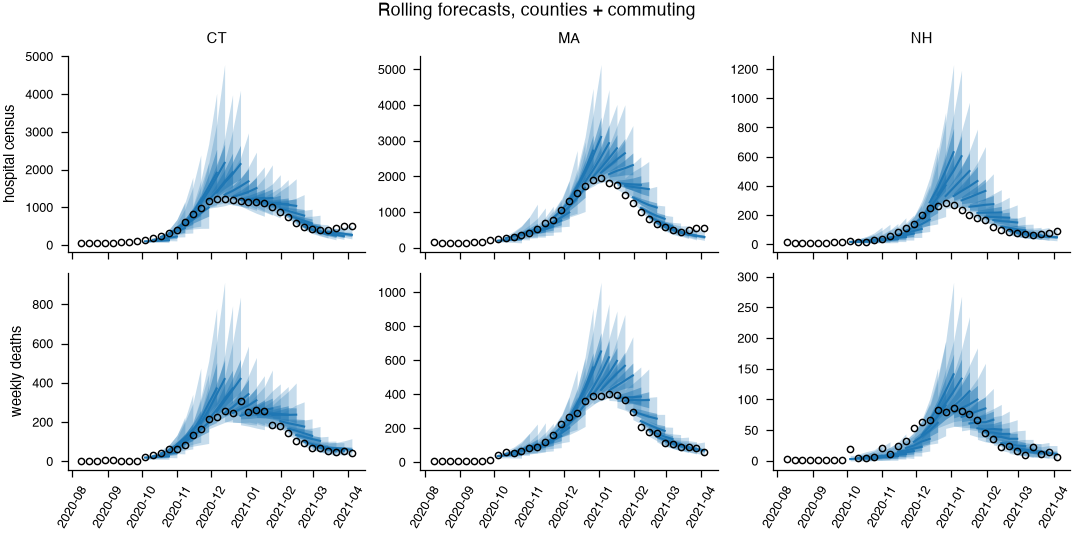

In [13]:
# Rolling forecasts at the scored scale, both quantities.
fig = ev_mod.figure_rolling_forecasts(ev, "movement")
save_figure(fig, "covid-rolling-forecasts", figure_dir=NOTEBOOK_FIGURES)
plt.show()

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


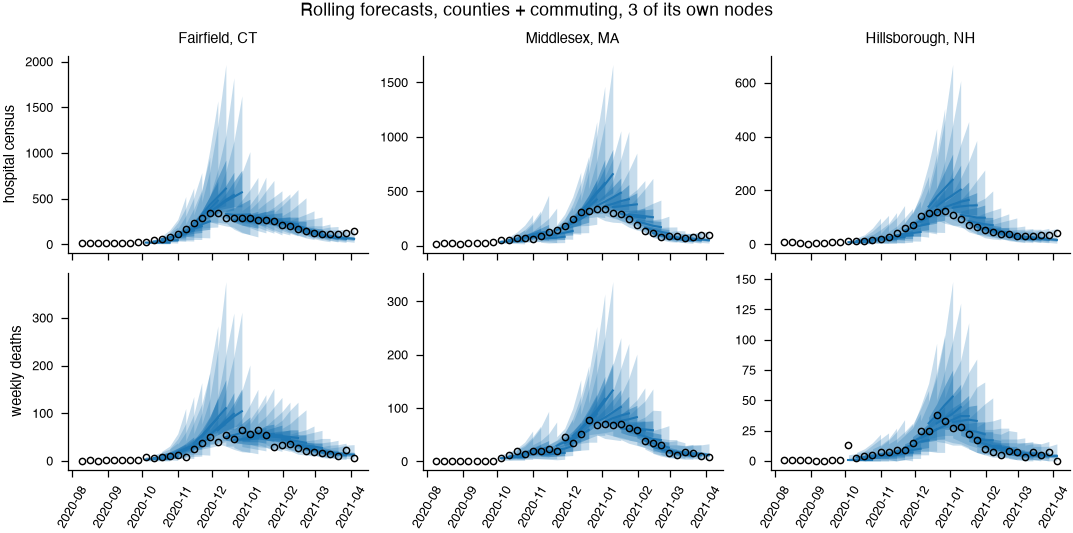

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


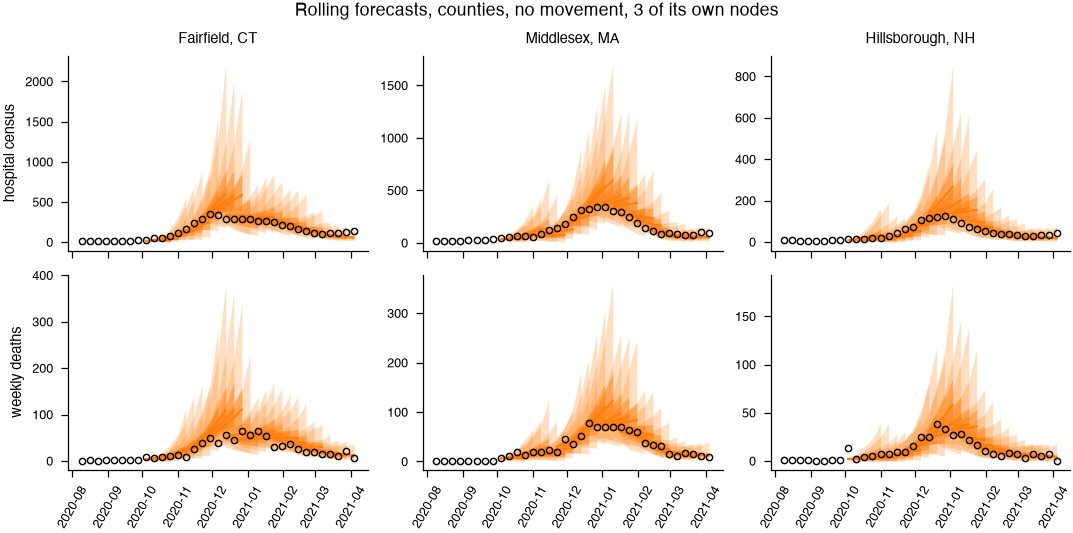

In [14]:
# The same rolling forecasts at COUNTY resolution: the model's own nodes rather than the
# 3 states it is scored at. Same `locations=` argument as `figure_fit`, and the same
# `demolib.plots.plot_rolling_forecasts` that draws Demo 1's panels, so the two demos
# cannot drift apart.
#
# This is the scale at which movement can show up at all: summing 32 partly independent
# counties cancels exactly the noise the movement model represents.
fig = ev_mod.figure_rolling_forecasts(ev, "movement", locations=FOCUS_COUNTIES)
save_figure(fig, "covid-county-rolling-forecasts", figure_dir=NOTEBOOK_FIGURES)
plt.show()

# Movement off at the same counties: the contrast the county-scale WIS ratio scores.
fig = ev_mod.figure_rolling_forecasts(ev, "county", locations=FOCUS_COUNTIES)
save_figure(fig, "covid-county-rolling-forecasts-no-movement", figure_dir=NOTEBOOK_FIGURES)
plt.show()

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


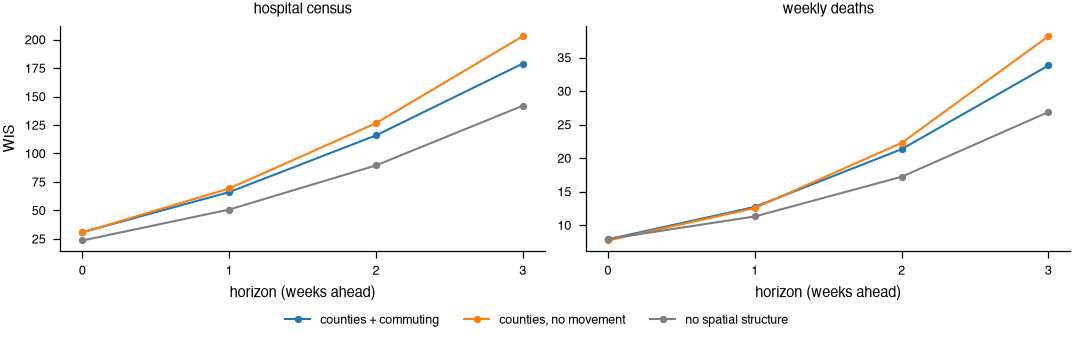

In [15]:
# Figure 3(c): skill against horizon, three models x two quantities.
fig = ev_mod.figure_wis_by_horizon(ev)
save_figure(fig, "covid-wis-by-horizon", figure_dir=NOTEBOOK_FIGURES)
plt.show()

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


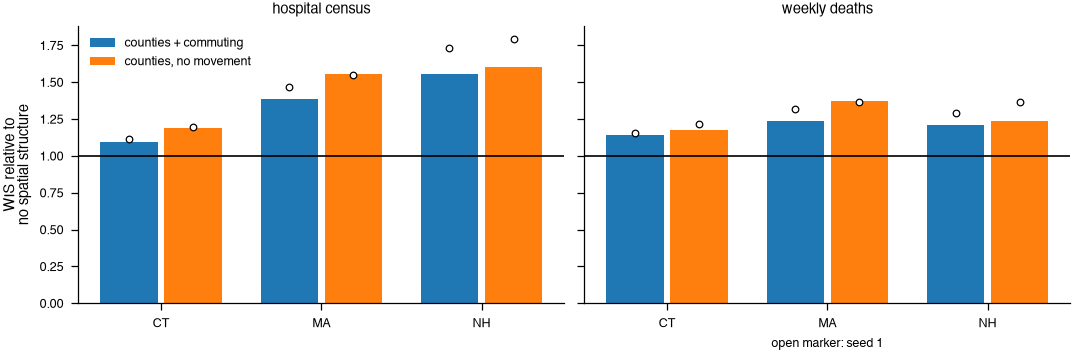

In [16]:
# Figure 3(d): per-state ratio against the baseline. Open markers are seed 1;
# where they sit on the other side of 1, that state's result is not reproducible.
fig = ev_mod.figure_relative_wis(ev, rep)
save_figure(fig, "covid-relative-wis", figure_dir=NOTEBOOK_FIGURES)
plt.show()

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


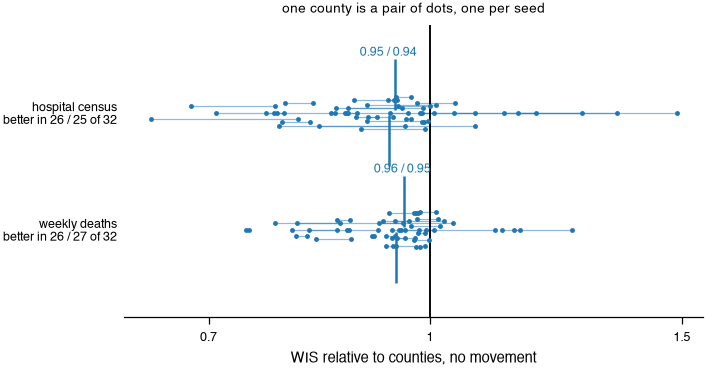

census: movement better in 26/32 (seed 0), 25/32 (seed 1); 7 counties flip
deaths: movement better in 26/32 (seed 0), 27/32 (seed 1); 7 counties flip


In [17]:
# The movement question at COUNTY resolution: 32 counties rather than 3 states, so this
# is the only Demo 2 panel with a real distribution. Same swarm as Demo 1's Figure 2(d) --
# both call `demolib.plots.plot_ratio_swarm`, so the two demos cannot drift apart.
#
# Drawn at the county scale deliberately: the state-scale comparison pools 32 partly
# independent nodes, which cancels exactly the noise the movement model represents.
#
# Pass `rep` to draw both seeds, or None for seed 0 alone. Both seeds are worth showing
# here even though the pooled numbers agree to 0.1%: the aggregate is reproducible but
# 7 of 32 counties change which model they favour between seeds.
fig = ev_mod.figure_county_relative_wis(ev, rep)
save_figure(fig, "covid-county-relative-wis", figure_dir=NOTEBOOK_FIGURES)
plt.show()

# The numbers behind it.
for quantity in ev_mod.QUANTITIES:
    ratios, counties = ev_mod.county_relative(ev, quantity)
    other, _ = ev_mod.county_relative(rep, quantity)
    flips = int(((ratios < 1) != (other < 1)).sum())
    print(f"{quantity}: movement better in {int((ratios < 1).sum())}/{len(ratios)} "
          f"(seed 0), {int((other < 1).sum())}/{len(other)} (seed 1); "
          f"{flips} counties flip")

### The composed figures

What `manuscript_analysis.demos.export` assembles the panels above into, and it has the same four
panels as Figure 2: one comparison run twice, along different axes.

| | Figure 3 | drawn by |
|---|---|---|
| (a) | the commuting matrix | `figure_movement_structure` |
| (b) | log WIS by horizon, both quantities | `figure_wis_by_horizon` |
| (c) | three counties, both quantities | `figure_fit` |
| (d) | per-county relative log WIS | `figure_county_relative_wis` |

These cells display but do not write files. `python -m manuscript_analysis.demos.export` is what writes `figures/`.


In [ ]:
# `export_manuscript` contributes layout only; every panel is a function from this
# module. Built from the objects already loaded above, so nothing is re-fitted.
fig = export.figure_3_covid(ev, rep)
plt.show()


In [ ]:
# The supplementary forecast figure: the same forecasts at the model's own counties
# (the darker shade) and at the three states they are summed into and scored at. The
# columns correspond, so a column is one place at two scales.
fig = export.figure_s_covid_forecasts(ev)
plt.show()


## 7. Calibration

Demo 2's half of the supplementary calibration figure, and the most robust thing here. The two spatial scales are
expected to miss in **opposite** directions, which supports a real methodological point: WIS
is an awkward adjudicator between forecasts at different spatial scales, because aggregating
partly-independent nodes cancels noise that a single node retains.

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


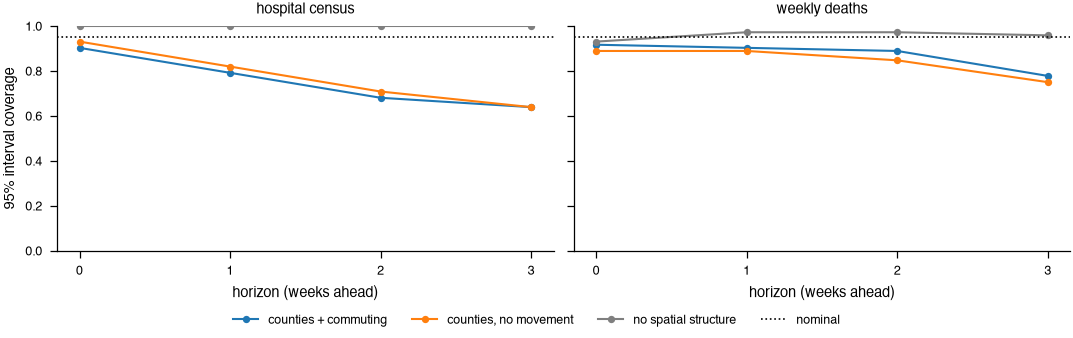

cov95  cov50
model    quantity              
movement census    0.753  0.295
         deaths    0.872  0.385
county   census    0.774  0.288
         deaths    0.844  0.382
state    census    1.000  0.510
         deaths    0.958  0.552

In [20]:
fig = ev_mod.figure_calibration(ev, nominal=0.95)
save_figure(fig, "covid-calibration", figure_dir=NOTEBOOK_FIGURES)
plt.show()

ev_mod.wis_table(ev)[["cov95", "cov50"]].round(3)

## 8. Summary

_Prose goes here once the R = 600 runs settle what can be claimed about movement._